# Within-run trajectories — dose, trait, and containment across 40 checkpoints per run

**Data: the strip ckpt-replay campaign** (`run_logs/strip_ckpt_replay_worker.py`): every
non-diverged run of the focus-teacher non-adaptive strip, retraced bit-identically with a
checkpoint every 625 steps of the ep20 / 25k-step budget. Three per-checkpoint readouts, one
JSON per (cell, ftseed) run in `analysis/`:

| readout | pass | definition |
|---|---|---|
| **dose** | `scripts.ckpt_dose_trajectory` | pooled mean over LoRA modules of $s\lVert BA\rVert/\lVert W_0\rVert$, in **both** norms; endpoint bit-equal to the harvest's `dw_fro`/`dw_spec` |
| **trait** | `scripts.ckpt_preference_trajectory` | the strip's own `test` prob readout (`p_target`), same prompts/CRN seeds as the endpoint eval |
| **containment** | `scripts.ckpt_pile_kl_trajectory` | KL(base ‖ checkpoint) on 32 held-out Pile docs, ~10.2k eligible logit positions, position-pooled nats |

Evidence class **[cal]**: the population is the outcome-independent strip; every cross-run
statistic below inherits the calibrated design. Two standing caveats: (i) **coverage is
whatever has drained** — §0 prints live counts, and until the replay completes the covered
half is *alphabetically biased across lr rungs*, so treat exponent fits as interim; (ii) the
grid is 625 steps — "death at step 625" means *at or before* the first checkpoint.

Findings first landed 2026-08-15; narrative home: `COLLAPSE_CLAIM_CHAIN.md` §A2
("the calibrated trajectory evidence").

## 0. Setup — load the three trajectory sets and align them per run

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from subliminal_learning.analysis.collapse_law import DEAD_SEED, K_of, KSTAR_POOLED
from subliminal_learning.analysis.plots import compare_table, right_legend
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()
AN = OUTPUT_ROOT / "analysis"

# House colors, fixed by entity across every figure in this notebook:
C_ALIVE, C_DEAD = "tab:blue", "tab:red"          # fate
C_F, C_S = "tab:blue", "tab:orange"              # norm (F solid, sigma dashed)
ALIVE_P95 = 2.09   # alive-mode Pile-KL P95 (nors_asks §4b) -- the containment ceiling
BASE_P = 0.0133    # ds1 base p(dog), animal_preference_test

harv = {(r["tag"], r["seed"]): r
        for r in json.loads((AN / "nonadaptive_8x7_harvest.json").read_text())}


def _points(path, key, guard=lambda p: True):
    if not path.exists():
        return None
    pts = [p for p in json.loads(path.read_text())["points"]
           if p["step"] is not None and p.get("checkpoint") != "checkpoints"
           and not p.get("nonfinite") and guard(p)]
    return pts if len(pts) >= 40 else None


runs = {}
for f in sorted((AN / "ckpt_dose_traj").glob("*.json")):
    d = json.loads(f.read_text())
    tag, seed = d["tag"], d["ftseed"]
    hr = harv.get((tag, seed))
    if hr is None or hr["diverged"] or hr.get("test_p") is None:
        continue
    if hr["alpha"] / hr["rank"] > 64:          # primary strip region only (s <= 64)
        continue
    dp = [p for p in d["points"] if p["step"] is not None]
    if len(dp) < 40:
        continue
    r = {"steps": np.array([p["step"] for p in dp]),
         "Df": np.array([p["D_fro"] for p in dp]),
         "Ds": np.array([p["D_spec"] for p in dp]), "hr": hr}
    pp = _points(AN / "ckpt_pref_traj" / f"{tag}_ftseed{seed}.json", "test",
                 guard=lambda p: "test" in p)
    kp = _points(AN / "ckpt_pile_kl_traj" / f"{tag}_ftseed{seed}.json", "kl")
    if pp:
        r["p"] = np.array([q["test"]["p_target"] for q in pp])
    if kp:
        r["kl"] = np.array([q["kl_base_adapted"] for q in kp])
    runs[(tag, seed)] = r

STEPS = next(iter(runs.values()))["steps"]
N_STEPS = STEPS[-1]
full = {k: r for k, r in runs.items() if "p" in r and "kl" in r}
print(f"dose trajectories: {len(runs)} runs | all three aligned: {len(full)} runs "
      f"(of 890 strip runs; the rest arrive as the replay + eval queues drain)")

# Per-rank ENDPOINT thresholds, both norms: 50% point of a per-rank logistic of fate on
# log endpoint dose, fitted on the FULL harvest (all 890 runs, not just covered ones).
h = pd.DataFrame([r for r in harv.values()
                  if not r["diverged"] and r.get("test_p") is not None and r.get("dw_fro")])
h = h[h.alpha / h["rank"] <= 64]
h["dead"] = (h.test_p < DEAD_SEED).astype(int)
TH = {}
for rk, g in h.groupby("rank"):
    TH[rk] = {}
    for col in ("dw_fro", "dw_spec"):
        m = smf.logit(f"dead ~ np.log({col})", g).fit(disp=0, maxiter=300)
        TH[rk][col] = float(np.exp(-m.params["Intercept"] / m.params[f"np.log({col})"]))
print("per-rank endpoint theta_F:", {k: round(v["dw_fro"], 4) for k, v in sorted(TH.items())})


def death_index(p):
    '''First checkpoint index at which p < DEAD_SEED and stays below to the end.'''
    below = p < DEAD_SEED
    for i in range(len(p)):
        if below[i] and below[i:].all():
            return i
    return None


def interp_cross(steps, traj, thr):
    '''Continuous crossing step of a (monotone-ish) trajectory, log-linear interpolation.'''
    ix = np.nonzero(traj >= thr)[0]
    if not len(ix):
        return None
    i = ix[0]
    if i == 0:
        return float(steps[0])
    y0, y1 = np.log(traj[i - 1] + 1e-12), np.log(traj[i])
    return float(steps[i - 1] + (steps[i] - steps[i - 1]) * (np.log(thr) - y0) / (y1 - y0))


rows = []
for (tag, seed), r in full.items():
    hr = r["hr"]; rk = hr["rank"]
    di = death_index(r["p"])
    rows.append(dict(
        tag=tag, seed=seed, rank=rk, alpha=hr["alpha"], lr=hr["lr"],
        K_rel=K_of(hr["lr"], hr["alpha"], rk) / KSTAR_POOLED,
        dead=int(hr["test_p"] < DEAD_SEED), test_p=hr["test_p"],
        death_step=float(STEPS[di]) if di is not None else np.nan,
        D_at_death=r["Df"][di] / TH[rk]["dw_fro"] if di is not None else np.nan,
        kl_at_death=r["kl"][di] if di is not None else np.nan,
        emerged=bool(r["p"][:max(di, 0) + 1].max() > 1.5 * BASE_P) if di is not None else np.nan,
        kl_end=r["kl"][-1], kl_max=r["kl"].max(),
        end_rel=r["Df"][-1] / TH[rk]["dw_fro"],
        over_end=float(r["Df"].max() / r["Df"][-1]),
        p_plateau=float(np.median(r["p"][-8:])),
    ))
df = pd.DataFrame(rows)
print(f"run table: {len(df)} rows (one per run with all three trajectories); "
      f"{df.dead.sum()} dead, {int(df.dead.sum() - df.death_step.notna().sum())} of them "
      "without a sustained death point")

dose trajectories: 890 runs | all three aligned: 890 runs (of 890 strip runs; the rest arrive as the replay + eval queues drain)
per-rank endpoint theta_F: {1: 0.1655, 2: 0.1476, 4: 0.1565, 8: 0.1425, 16: 0.131, 32: 0.1246, 64: 0.1117, 128: 0.1053}
run table: 890 rows (one per run with all three trajectories); 371 dead, 0 of them without a sustained death point


## 1. The trajectory gallery — what one run looks like

**Row unit: one run** (cell × ftseed). Three panels share the x-axis (training step):
pooled dose in θ̂ units (F solid, σ dashed; grey line = the endpoint threshold, dotted grey
= the 0.35×θ̂ trajectory threshold of §4), the trait probability (log scale; grey = base
prior, dotted = the DEAD cut), and Pile KL vs base (grey = the alive-mode P95 ceiling).
Rows are picked **by rule**: the deepest covered dead run, the covered alive run closest to
the boundary, the latest death, and both seeds of the first covered mixed-fate cell.

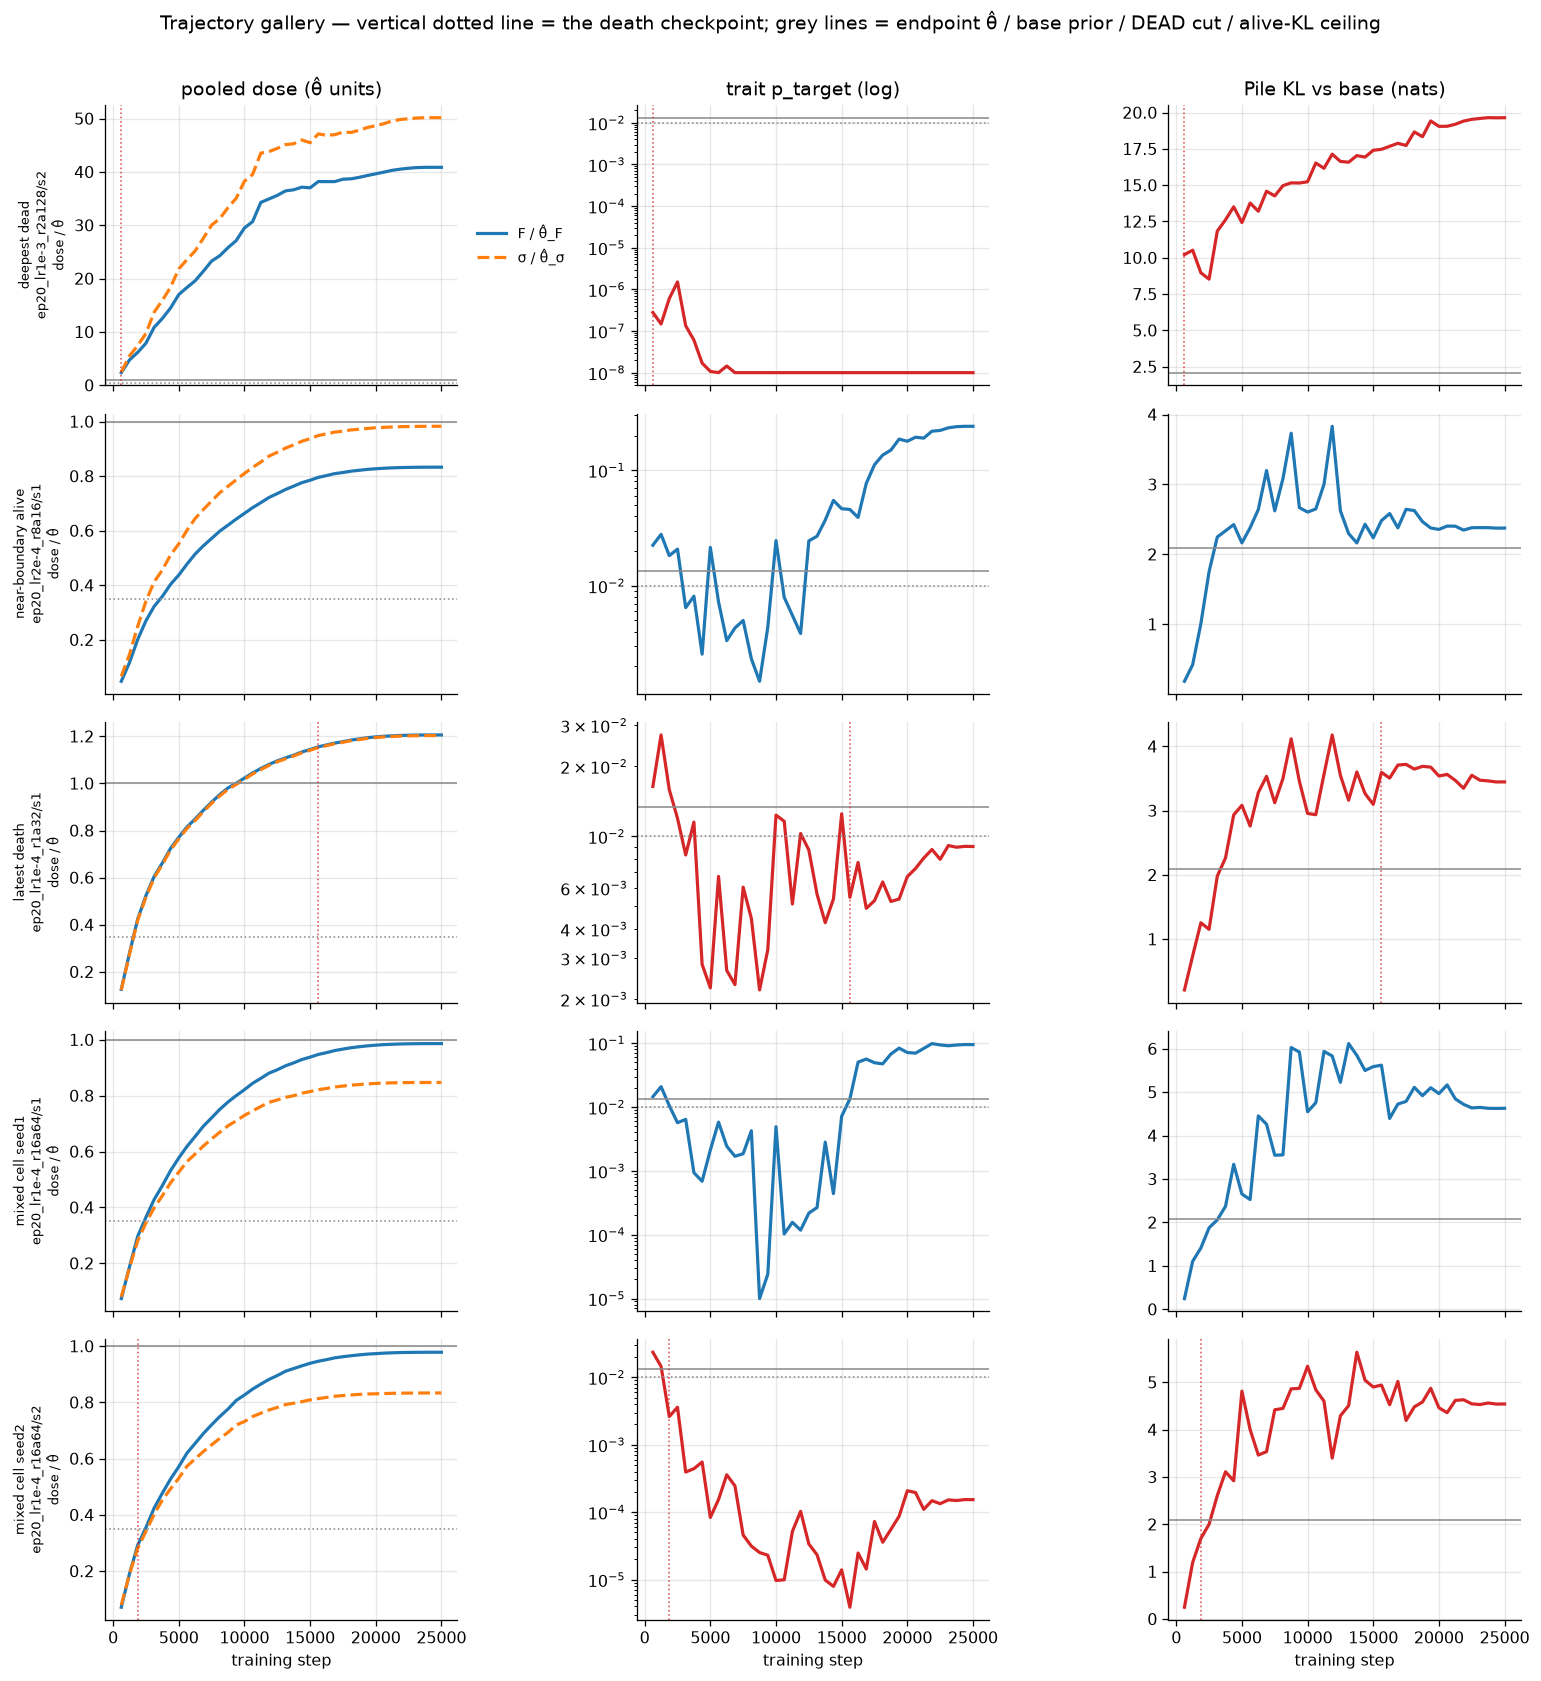

In [2]:
sel = []
dcov = df.dropna(subset=["death_step"])
sel.append(("deepest dead", tuple(df.loc[df[df.dead == 1].K_rel.idxmax(), ["tag", "seed"]])))
al = df[df.dead == 0]
sel.append(("near-boundary alive", tuple(df.loc[(al.K_rel - 1).abs().idxmin(), ["tag", "seed"]])))
sel.append(("latest death", tuple(df.loc[dcov.death_step.idxmax(), ["tag", "seed"]])))
mixed_tags = [t for t, g in df.groupby("tag") if len(g) == 2 and g.dead.nunique() == 2]
if mixed_tags:
    for s_ in (1, 2):
        sel.append((f"mixed cell seed{s_}", (mixed_tags[0], s_)))

fig, axes = plt.subplots(len(sel), 3, figsize=(13.5, 2.9 * len(sel)), sharex=True)
for row, (label, key) in enumerate(sel):
    r = full[key]; hr = r["hr"]; rk = hr["rank"]
    fate_c = C_DEAD if harv[key]["test_p"] < DEAD_SEED else C_ALIVE
    axd, axp, axk = axes[row]
    axd.plot(r["steps"], r["Df"] / TH[rk]["dw_fro"], color=C_F, lw=2, label="F / θ̂_F")
    axd.plot(r["steps"], r["Ds"] / TH[rk]["dw_spec"], color=C_S, lw=2, ls="--", label="σ / θ̂_σ")
    axd.axhline(1.0, color="0.55", lw=1)
    axd.axhline(0.35, color="0.55", lw=1, ls=":")
    axd.set_ylabel(f"{label}\n{key[0]}/s{key[1]}\ndose / θ̂", fontsize=8)
    axp.plot(r["steps"], np.clip(r["p"], 1e-8, None), color=fate_c, lw=2)
    axp.set_yscale("log"); axp.axhline(BASE_P, color="0.55", lw=1)
    axp.axhline(DEAD_SEED, color="0.55", lw=1, ls=":")
    axk.plot(r["steps"], r["kl"], color=fate_c, lw=2)
    axk.axhline(ALIVE_P95, color="0.55", lw=1)
    di = death_index(r["p"])
    if di is not None:
        for ax in (axd, axp, axk):
            ax.axvline(STEPS[di], color=fate_c, lw=1, ls=":", alpha=0.8)
    if row == 0:
        axd.set_title("pooled dose (θ̂ units)"); axp.set_title("trait p_target (log)")
        axk.set_title("Pile KL vs base (nats)")
        right_legend(axd)
for ax in axes[-1]:
    ax.set_xlabel("training step")
fig.suptitle("Trajectory gallery — vertical dotted line = the death checkpoint; "
             "grey lines = endpoint θ̂ / base prior / DEAD cut / alive-KL ceiling", y=1.005)
plt.tight_layout(); plt.show()

## 2. Natural trajectories are monotone — the overshoot configuration does not exist

**Row unit: one run; statistic: max-over-training / endpoint of the pooled F dose.** If
training ever overshot the threshold and relaxed back below it, this ratio would exceed 1
by a margin in some runs. It does not: the endpoint *is* the running peak, so
"exceeded θ̂ at any point" and "endpoint exceeds θ̂" are the same event in natural training —
the trajectory-vs-endpoint distinction lives entirely in *timing* (§3–§4), or in
interventions (the clamp).

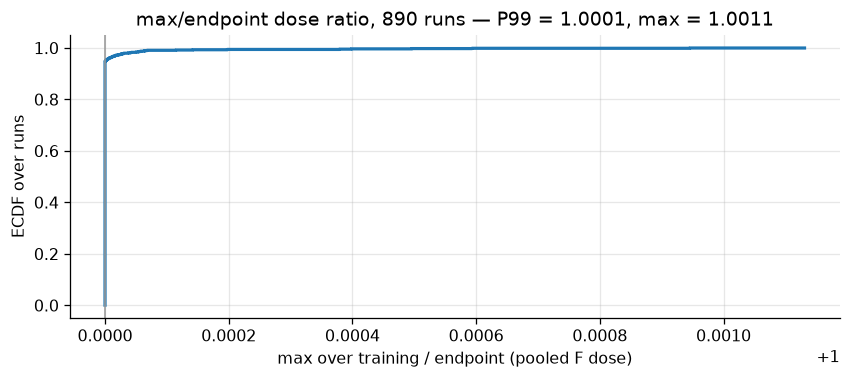

runs that crossed theta_F mid-run but ended below it: 0


In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
v = np.sort(df.over_end.values)
ax.step(v, np.arange(1, len(v) + 1) / len(v), color=C_F, lw=2)
ax.set_xlabel("max over training / endpoint (pooled F dose)")
ax.set_ylabel("ECDF over runs")
ax.set_title(f"max/endpoint dose ratio, {len(df)} runs — "
             f"P99 = {np.quantile(df.over_end, .99):.4f}, max = {df.over_end.max():.4f}")
ax.axvline(1.0, color="0.6", lw=1)
plt.tight_layout(); plt.show()
print(f"runs that crossed theta_F mid-run but ended below it: "
      f"{int(((df.over_end * df.end_rel >= 1) & (df.end_rel < 1)).sum())}")

## 3. When runs die — and when the decision is readable

Left — **row unit: one dead run**; x = its death checkpoint (first sustained below-cut
point), y = its design depth K/K*; marker filled where the trait had emerged (p > 1.5× base)
before death. Deep cells die at the first checkpoint; late deaths are exclusively
near-boundary, and emergence-before-death is a near-boundary phenomenon.
Right — **decision time**: at each checkpoint, the AUC of endpoint fate predicted by the
trait probability at that checkpoint alone, over all aligned runs. It reaches 1.000 at
step 1250 — 5% of training.

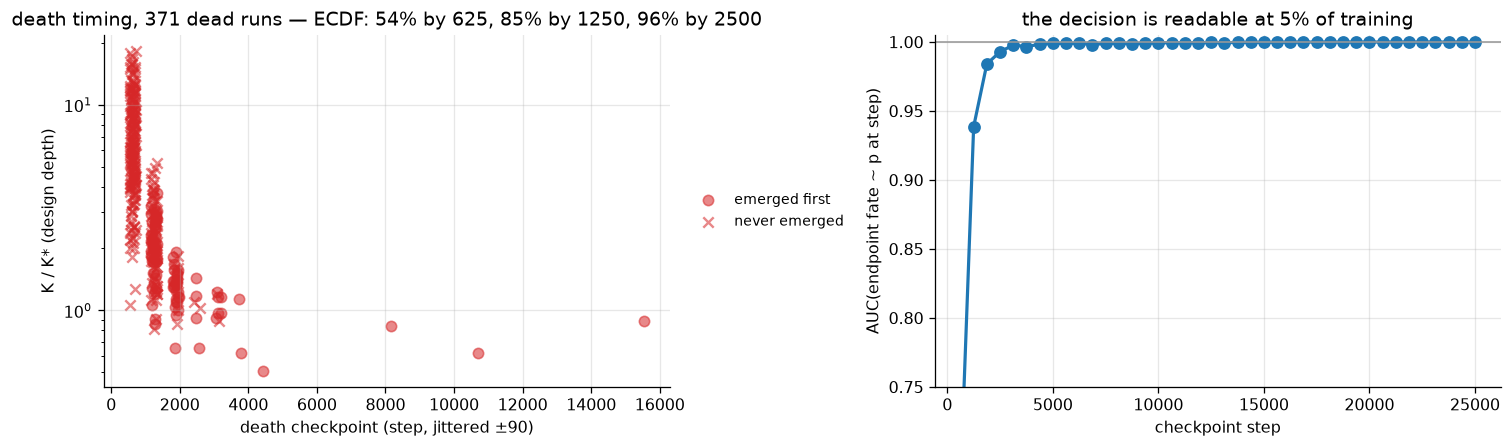

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
dd = df.dropna(subset=["death_step"])
for em, mk, lab in ((True, "o", "emerged first"), (False, "x", "never emerged")):
    g = dd[dd.emerged == em]
    ax1.scatter(g.death_step + np.random.default_rng(0).uniform(-90, 90, len(g)),
                g.K_rel, s=42, marker=mk, color=C_DEAD, alpha=0.55, label=lab)
ax1.set_yscale("log"); ax1.set_xlabel("death checkpoint (step, jittered ±90)")
ax1.set_ylabel("K / K* (design depth)")
ax1.set_title(f"death timing, {len(dd)} dead runs — ECDF: "
              f"{(dd.death_step <= 625).mean():.0%} by 625, "
              f"{(dd.death_step <= 1250).mean():.0%} by 1250, "
              f"{(dd.death_step <= 2500).mean():.0%} by 2500")
right_legend(ax1)

from sklearn.metrics import roc_auc_score
y = [df.loc[i, "dead"] for i in df.index]
aucs = [roc_auc_score(y, [-full[(df.loc[i, "tag"], df.loc[i, "seed"])]["p"][j]
                          for i in df.index]) for j in range(len(STEPS))]
ax2.plot(STEPS, aucs, "o-", ms=7, lw=2, color=C_F)
ax2.set_xlabel("checkpoint step"); ax2.set_ylabel("AUC(endpoint fate ~ p at step)")
ax2.set_ylim(0.75, 1.005); ax2.axhline(1.0, color="0.6", lw=1)
ax2.set_title("the decision is readable at 5% of training")
plt.tight_layout(); plt.show()

## 4. Dose at death, and the in-flight threshold

Left — **row unit: one dead run**; y = its pooled F dose *at the death checkpoint* in
endpoint-θ̂ units, grouped by design depth. Most deaths happen *below* the endpoint
threshold: the endpoint dose the law thresholds on is mostly post-mortem accumulation.
Right — the **trajectory threshold**: over deaths late enough to time (death ≥ step 1250),
the median |death step − crossing step of c·θ̂| as a function of the level c, per norm.
The minimum is the operative in-flight threshold; on current coverage it sits near
**0.35×θ̂ (F)** / 0.45×θ̂ (σ), with neither norm clearly better — the trajectory norm race
(A4) is unresolved at this n.

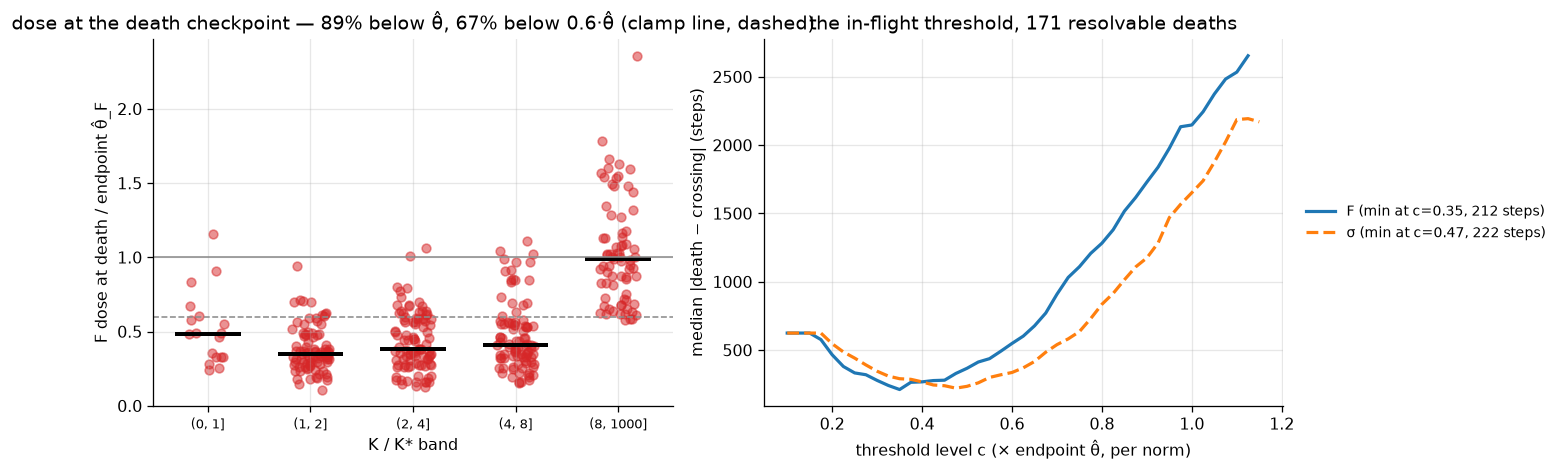

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
dd = df.dropna(subset=["death_step", "D_at_death"])
bands = pd.cut(dd.K_rel, [0, 1, 2, 4, 8, 1000])
rng = np.random.default_rng(0)
for i, (band, g) in enumerate(dd.groupby(bands, observed=True)):
    ax1.scatter(i + rng.uniform(-0.18, 0.18, len(g)), g.D_at_death, s=30,
                color=C_DEAD, alpha=0.5)
    ax1.plot([i - 0.3, i + 0.3], [g.D_at_death.median()] * 2, color="k", lw=2.5)
ax1.set_xticks(range(bands.cat.categories.size),
               [str(c) for c in bands.cat.categories], fontsize=8)
ax1.axhline(1.0, color="0.55", lw=1); ax1.axhline(0.6, color="0.55", lw=1, ls="--")
ax1.set_xlabel("K / K* band"); ax1.set_ylabel("F dose at death / endpoint θ̂_F")
ax1.set_title(f"dose at the death checkpoint — {(dd.D_at_death < 1).mean():.0%} below θ̂, "
              f"{(dd.D_at_death < 0.6).mean():.0%} below 0.6·θ̂ (clamp line, dashed)")

res = [(k, full[k]) for k in full
       if not np.isnan(df.set_index(["tag", "seed"]).loc[k, "death_step"])
       and df.set_index(["tag", "seed"]).loc[k, "death_step"] >= 1250]
cs = np.arange(0.1, 1.31, 0.025)
for nm, tcol, thcol, color, ls in (("F", "Df", "dw_fro", C_F, "-"),
                                   ("σ", "Ds", "dw_spec", C_S, "--")):
    med = []
    for c in cs:
        e = [abs(t - df.set_index(["tag", "seed"]).loc[k, "death_step"])
             for k, r in res
             if (t := interp_cross(r["steps"], r[tcol], c * TH[r["hr"]["rank"]][thcol]))
             is not None]
        med.append(np.median(e) if len(e) >= 0.9 * len(res) else np.nan)
    ax2.plot(cs, med, color=color, ls=ls, lw=2, label=f"{nm} (min at c="
             f"{cs[np.nanargmin(med)]:.2f}, {np.nanmin(med):.0f} steps)")
ax2.set_xlabel("threshold level c (× endpoint θ̂, per norm)")
ax2.set_ylabel("median |death − crossing| (steps)")
ax2.set_title(f"the in-flight threshold, {len(res)} resolvable deaths")
right_legend(ax2)
plt.tight_layout(); plt.show()

## 5. What a death *is* — containment failure, mostly

**Row unit: one dead run.** x = death checkpoint, y = Pile KL at that checkpoint (log);
horizontal line = the alive-mode ceiling (P95 = 2.09 nats). 87% of deaths sit above the
ceiling *at the moment of trait death* — trait loss and containment failure co-occur
within one 625-step window; the KL-quiet minority concentrates at K/K* 1–4 and is the one
candidate for a distinct trait-first mode. The table is the four-way census.

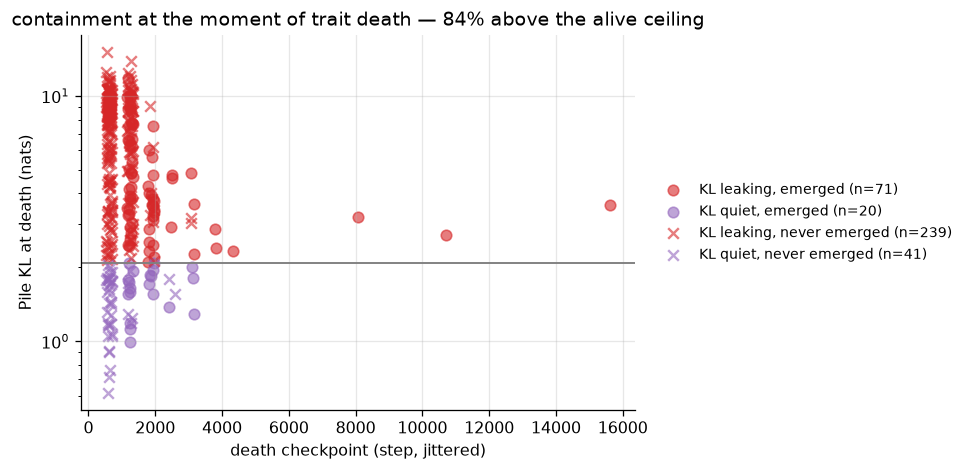

,never emerged,trait emerged
KL leaking,239,71
KL quiet,41,20


row unit: one dead run with a sustained death point; 'emerged' = p exceeded 1.5x base prior at some checkpoint at or before death


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
dd = df.dropna(subset=["death_step", "kl_at_death"])
for em, mk in ((True, "o"), (False, "x")):
    for quiet, color, lab in ((False, C_DEAD, "KL leaking"), (True, "tab:purple", "KL quiet")):
        g = dd[(dd.emerged == em) & ((dd.kl_at_death <= ALIVE_P95) == quiet)]
        ax.scatter(g.death_step + np.random.default_rng(1).uniform(-90, 90, len(g)),
                   g.kl_at_death.clip(lower=1e-2), s=44, marker=mk, color=color, alpha=0.6,
                   label=f"{lab}, {'emerged' if em else 'never emerged'} (n={len(g)})")
ax.set_yscale("log"); ax.axhline(ALIVE_P95, color="0.5", lw=1.2)
ax.set_xlabel("death checkpoint (step, jittered)"); ax.set_ylabel("Pile KL at death (nats)")
ax.set_title(f"containment at the moment of trait death — "
             f"{(dd.kl_at_death > ALIVE_P95).mean():.0%} above the alive ceiling")
right_legend(ax)
plt.tight_layout(); plt.show()
tab = dd.groupby([np.where(dd.kl_at_death > ALIVE_P95, "KL leaking", "KL quiet"),
                  np.where(dd.emerged.astype(bool), "trait emerged", "never emerged")]
                 ).size().unstack(fill_value=0)
display(compare_table(tab))
print("row unit: one dead run with a sustained death point; 'emerged' = p exceeded "
      "1.5x base prior at some checkpoint at or before death")

## 6. Decision ≠ expression — transfer keeps building after fate is settled

Left — **alive runs' trait trajectories** (one faint line per run, colored by K/K* band;
thick lines = band medians). Fate is readable at step 1250 (§3) but the level plateaus at
median ~70% of training, and no alive run overshoots its own endpoint and declines.
Right — the decomposition: plateau level (median of the last 8 checkpoints) and
time-to-half-plateau per band. Acquisition is *slower* near the boundary while the plateau
is humped — the transfer hump is dose-impeded consolidation, not fast-acquisition-then-erosion.

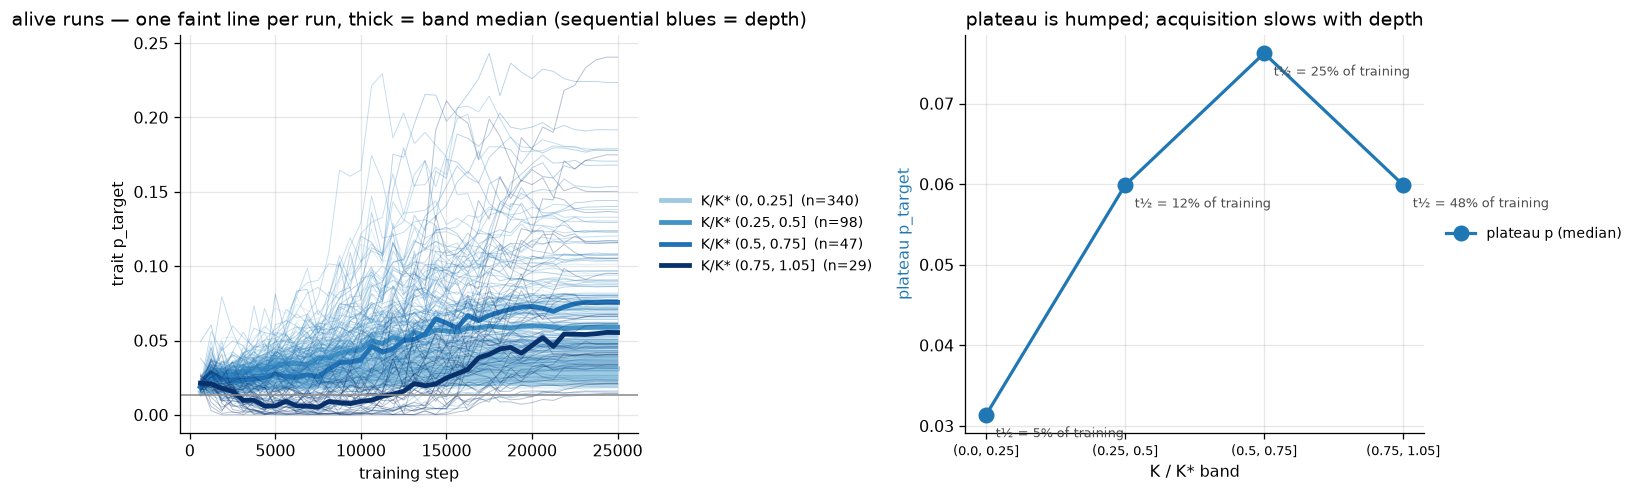

,n,plateau,t_half
K_rel,,,
"(0.0, 0.25]",335,0.031,1250.000
"(0.25, 0.5]",96,0.060,3125.000
"(0.5, 0.75]",45,0.076,6250.000
"(0.75, 1.05]",26,0.060,11875.000


row unit: one ALIVE run with plateau p > 0.02; plateau = median p over the last 8 checkpoints; t_half = first step reaching half the run's own plateau


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.4))
bands = [(0, .25, "#9ecae1"), (.25, .5, "#4292c6"), (.5, .75, "#2171b5"), (.75, 1.05, "#08306b")]
for lo, hi, color in bands:
    ks = [k for k in full if df.set_index(["tag", "seed"]).loc[k, "dead"] == 0
          and lo < df.set_index(["tag", "seed"]).loc[k, "K_rel"] <= hi]
    if not ks:
        continue
    for k in ks:
        ax1.plot(STEPS, full[k]["p"], color=color, lw=0.6, alpha=0.30)
    ax1.plot(STEPS, np.median([full[k]["p"] for k in ks], axis=0), color=color, lw=3,
             label=f"K/K* ({lo}, {hi}]  (n={len(ks)})")
ax1.axhline(BASE_P, color="0.55", lw=1)
ax1.set_xlabel("training step"); ax1.set_ylabel("trait p_target")
ax1.set_title("alive runs — one faint line per run, thick = band median (sequential blues = depth)")
right_legend(ax1)

alv = df[(df.dead == 0) & (df.p_plateau > 0.02)].copy()
alv["t_half"] = [float(STEPS[np.argmax(full[(t, s)]["p"] >= 0.5 * pl)])
                 for t, s, pl in zip(alv.tag, alv.seed, alv.p_plateau)]
g = alv.groupby(pd.cut(alv.K_rel, [0, .25, .5, .75, 1.05]), observed=True).agg(
    n=("t_half", "size"), plateau=("p_plateau", "median"), t_half=("t_half", "median"))
x = np.arange(len(g))
ax2.plot(x, g.plateau, "o-", ms=9, lw=2, color=C_ALIVE, label="plateau p (median)")
ax2.set_ylabel("plateau p_target", color=C_ALIVE)
ax2.set_xticks(x, [str(i) for i in g.index], fontsize=8); ax2.set_xlabel("K / K* band")
ax2.set_title("plateau is humped; acquisition slows with depth")
ax2b_vals = (g.t_half / N_STEPS)
for xi, (pl, th) in enumerate(zip(g.plateau, ax2b_vals)):
    ax2.annotate(f"t½ = {th:.0%} of training", (xi, pl), textcoords="offset points",
                 xytext=(6, -14), fontsize=8, color="0.3")
right_legend(ax2)
plt.tight_layout(); plt.show()
display(compare_table(g.round(3)))
print("row unit: one ALIVE run with plateau p > 0.02; plateau = median p over the last 8 "
      "checkpoints; t_half = first step reaching half the run's own plateau")

## 7. Containment recovery, and the mixed-fate cells

Left — **row unit: one alive run**; max KL over training vs endpoint KL. Points above the
diagonal recovered from a transient; several near-boundary runs recede from multi-nat peaks.
Right — **the mixed-fate cells** (identical HPs, near-identical dose, opposite fates): both
seeds' KL trajectories overlaid per cell. The alive and dead seed ride essentially the same
containment trajectory (endpoint differences ~0.1–1 nat against a 100–1000× trait gap) —
within-cell fate is orthogonal to realized damage, so the unnamed direction factor is
trait-channel-specific, not a damage-level factor.

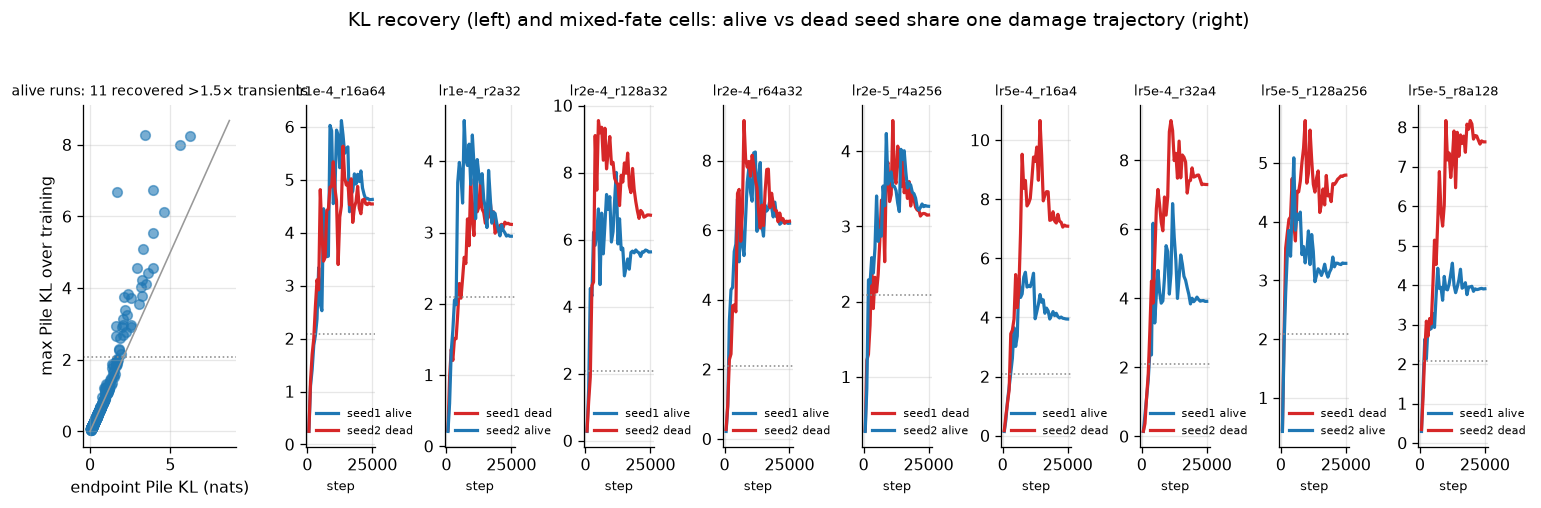

mixed-fate cells aligned so far: 9 of 9 (the census of all strip cells whose seeds split alive/dead); max recovered transient among alive runs: 8.3 nats


In [8]:
mixed_avail = [t for t in mixed_tags if all((t, s) in full for s in (1, 2))]
ncol = max(len(mixed_avail), 1)
fig = plt.figure(figsize=(13.5, 4.2))
gs = fig.add_gridspec(1, 2 + ncol, width_ratios=[2.2] + [1] * ncol + [0.001])
ax1 = fig.add_subplot(gs[0, 0])
al = df[df.dead == 0]
ax1.scatter(al.kl_end, al.kl_max, s=36, color=C_ALIVE, alpha=0.6)
lim = max(al.kl_max.max(), al.kl_end.max()) * 1.05
ax1.plot([0, lim], [0, lim], color="0.6", lw=1)
ax1.axhline(ALIVE_P95, color="0.55", lw=1, ls=":")
ax1.set_xlabel("endpoint Pile KL (nats)"); ax1.set_ylabel("max Pile KL over training")
n_rec = int((al.kl_max > 1.5 * al.kl_end).sum())
ax1.set_title(f"alive runs: {n_rec} recovered >1.5× transients", fontsize=9)
for j, t in enumerate(mixed_avail):
    ax = fig.add_subplot(gs[0, 1 + j])
    for s in (1, 2):
        fate_dead = harv[(t, s)]["test_p"] < DEAD_SEED
        ax.plot(STEPS, full[(t, s)]["kl"], color=C_DEAD if fate_dead else C_ALIVE, lw=2,
                label=f"seed{s} {'dead' if fate_dead else 'alive'}")
    ax.axhline(ALIVE_P95, color="0.55", lw=1, ls=":")
    ax.set_title(t.replace("ep20_", ""), fontsize=8)
    ax.set_xlabel("step", fontsize=8)
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("KL recovery (left) and mixed-fate cells: alive vs dead seed share one "
             "damage trajectory (right)", y=1.04)
plt.tight_layout(); plt.show()
print(f"mixed-fate cells aligned so far: {len(mixed_avail)} of 9 "
      "(the census of all strip cells whose seeds split alive/dead); "
      f"max recovered transient among alive runs: {al.kl_max.max():.1f} nats")

## 8. The dose law in time — calibrated exponents per checkpoint

**Row unit of each fit: one run with a dose trajectory** (fate never enters). At every
checkpoint, OLS of log pooled-F-dose on (log lr, log α, log r); ribbons = ±2 SE. The lr
exponent grows from ~0.7 at the first checkpoint to its late-time ~1.1, α is flat
throughout, rank relaxes. The shaded region is warmup (5% of steps) — separate that before
reading the early lr exponent mechanistically. *Interim caveat: until the replay drains the
covered runs are an lr-biased subset; exponents will firm up at full coverage.*

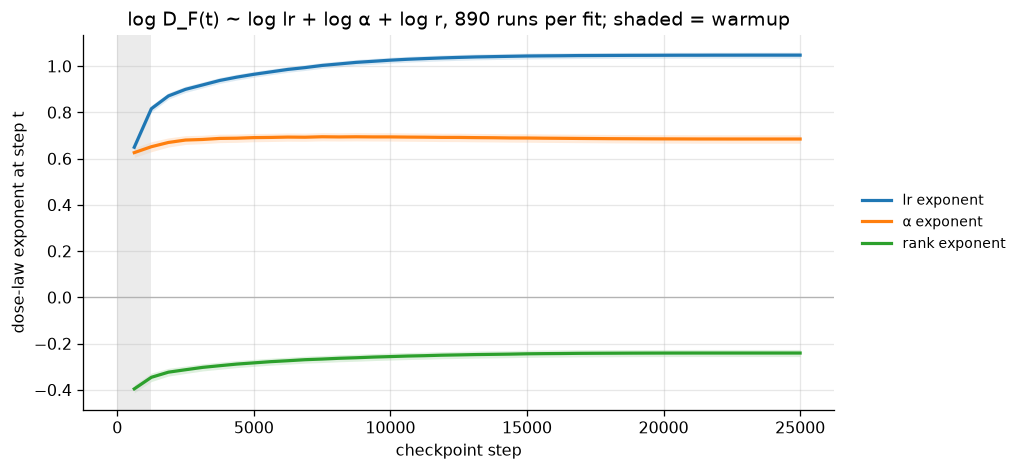

In [9]:
sel_idx = list(range(0, 40))
ex = {"llr": [], "la": [], "lrk": []}; se = {k: [] for k in ex}
dr = pd.DataFrame([dict(lr=r["hr"]["lr"], alpha=r["hr"]["alpha"], rank=r["hr"]["rank"],
                        **{f"D{i}": v for i, v in enumerate(r["Df"])})
                   for r in runs.values()])
for i in sel_idx:
    d_ = dr[dr[f"D{i}"] > 0].assign(y=lambda x: np.log(x[f"D{i}"]), llr=np.log(dr.lr),
                                    la=np.log(dr.alpha), lrk=np.log(dr["rank"]))
    m = smf.ols("y ~ llr + la + lrk", d_).fit()
    for k in ex:
        ex[k].append(m.params[k]); se[k].append(m.bse[k])
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, lab, color in (("llr", "lr exponent", C_F), ("la", "α exponent", C_S),
                      ("lrk", "rank exponent", "tab:green")):
    v, s_ = np.array(ex[k]), np.array(se[k])
    ax.plot(STEPS[sel_idx], v, lw=2, color=color, label=lab)
    ax.fill_between(STEPS[sel_idx], v - 2 * s_, v + 2 * s_, color=color, alpha=0.15, lw=0)
ax.axvspan(0, 0.05 * N_STEPS, color="0.85", alpha=0.5, lw=0)
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xlabel("checkpoint step"); ax.set_ylabel("dose-law exponent at step t")
ax.set_title(f"log D_F(t) ~ log lr + log α + log r, {len(dr)} runs per fit; "
             "shaded = warmup")
right_legend(ax)
plt.tight_layout(); plt.show()

## 9. Ledger — what this notebook establishes, and what waits for full coverage

Established on the interim population (all **[cal]**, direction unlikely to move):

1. Natural dose trajectories are **monotone** — no overshoot configuration exists (§2).
2. The fate decision is readable at **5% of training** (§3), while expression keeps
   building to a ~70%-of-training plateau (§6) — decision ≠ expression, and the transfer
   hump is a cross-dose shape, not a within-run time course.
3. Deaths happen early (59% at the first checkpoint) and at **sub-threshold dose**
   (median 0.50×θ̂; in-flight threshold ≈ 0.35×θ̂), consistent with the clamp's ~0.6×θ̂ —
   the endpoint dose is mostly post-mortem accumulation (§4).
4. Deaths are overwhelmingly **containment failures** (87% leak KL at the death
   checkpoint); the KL-quiet minority sits at K/K* 1–4 (§5).
5. Containment stress is **recoverable** near the boundary, and mixed-fate seeds share one
   damage trajectory — the within-cell fate factor is trait-channel-specific (§7).

Waiting on the full drain: the exposure-timing mediation retest of M's p = 1.3e-3 lr
residual (needs all 890 runs; the covered half separates), the F-vs-σ race at the death
clock with real n (§4-right is a tie so far), the remaining 5 mixed pairs, and the free
ep5/ep10 readout of K*(T)/θ(T) (lr-biased subset would distort it today). Re-running this
notebook after the campaign drains refreshes every figure.